# Datenexploration

## Init

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '../../data/raw/sickness_table.csv'

df = pd.read_csv(file_path)

# Explorative Datenanalyse (EDA)

In [15]:
# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Dateninspektion
display(df.info())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1152 entries, 0 to 1151
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Unnamed: 0  1152 non-null   int64         
 1   date        1152 non-null   datetime64[ns]
 2   n_sick      1152 non-null   int64         
 3   calls       1152 non-null   float64       
 4   n_duty      1152 non-null   int64         
 5   n_sby       1152 non-null   int64         
 6   sby_need    1152 non-null   float64       
 7   dafted      1152 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(4)
memory usage: 72.1 KB


None

,Unnamed: 0,date,n_sick,calls,n_duty,n_sby,sby_need,dafted
count,1152.000000,1152,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000
mean,575.500000,2017-10-28 12:00:00,68.808160,7919.531250,1820.572917,90.0,34.718750,16.335938
min,0.000000,2016-04-01 00:00:00,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000
25%,287.750000,2017-01-13 18:00:00,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000
50%,575.500000,2017-10-28 12:00:00,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000
75%,863.250000,2018-08-12 06:00:00,78.000000,8827.500000,1900.000000,90.0,12.250000,0.000000
max,1151.000000,2019-05-27 00:00:00,119.000000,11850.000000,1900.000000,90.0,555.000000,465.000000
std,332.698061,NaN,14.293942,1290.063571,80.086953,0.0,79.694251,53.394089


In [16]:
display(df)

,Unnamed: 0,date,n_sick,calls,n_duty,n_sby,sby_need,dafted
0,0,2016-04-01,73,8154.0,1700,90,4.0,0.0
1,1,2016-04-02,64,8526.0,1700,90,70.0,0.0
2,2,2016-04-03,68,8088.0,1700,90,0.0,0.0
3,3,2016-04-04,71,7044.0,1700,90,0.0,0.0
4,4,2016-04-05,63,7236.0,1700,90,0.0,0.0
...,...,...,...,...,...,...,...,...
1147,1147,2019-05-23,86,8544.0,1900,90,0.0,0.0
1148,1148,2019-05-24,81,8814.0,1900,90,0.0,0.0
1149,1149,2019-05-25,76,9846.0,1900,90,146.0,56.0
1150,1150,2019-05-26,83,9882.0,1900,90,160.0,70.0


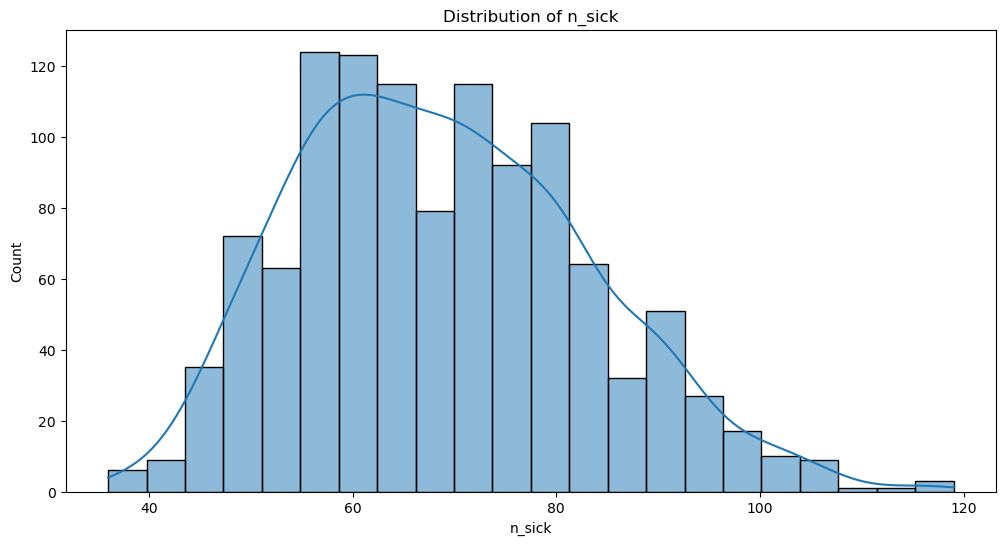

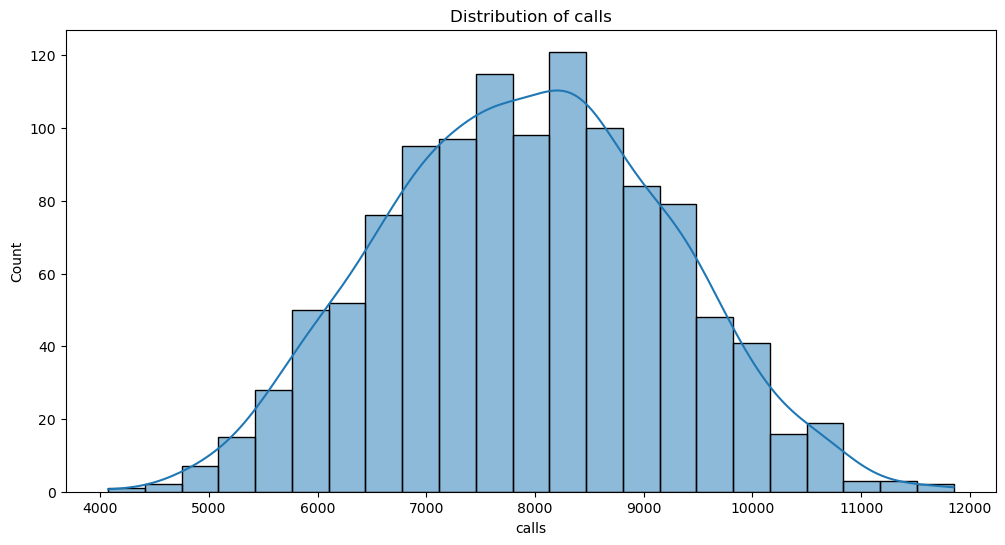

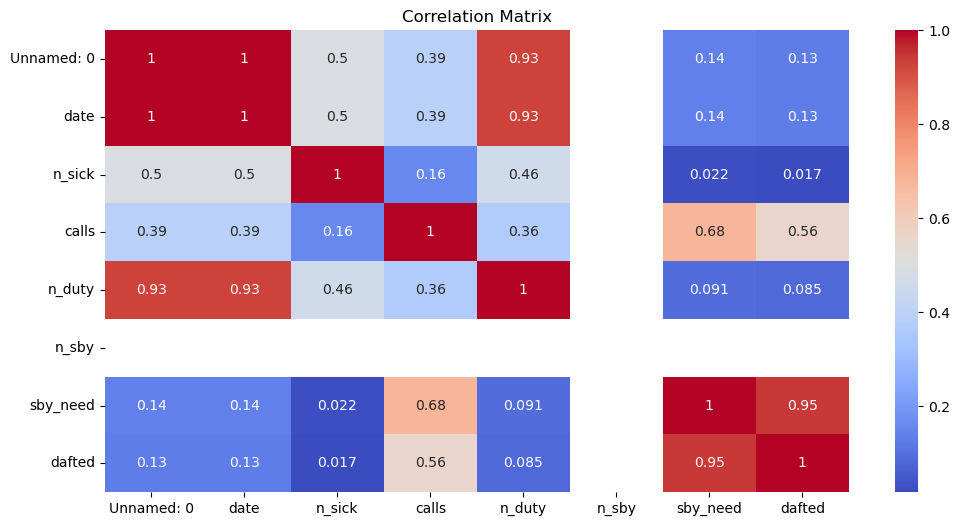

In [4]:
# Visualisierungen
plt.figure(figsize=(12, 6))
sns.histplot(df['n_sick'], kde=True)
plt.title('Distribution of n_sick')
plt.show()

plt.figure(figsize=(12, 6))
sns.histplot(df['calls'], kde=True)
plt.title('Distribution of calls')
plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

#To-Do: Visualiserung und Verteilung der Anrufe ist evtl. nicht ideal

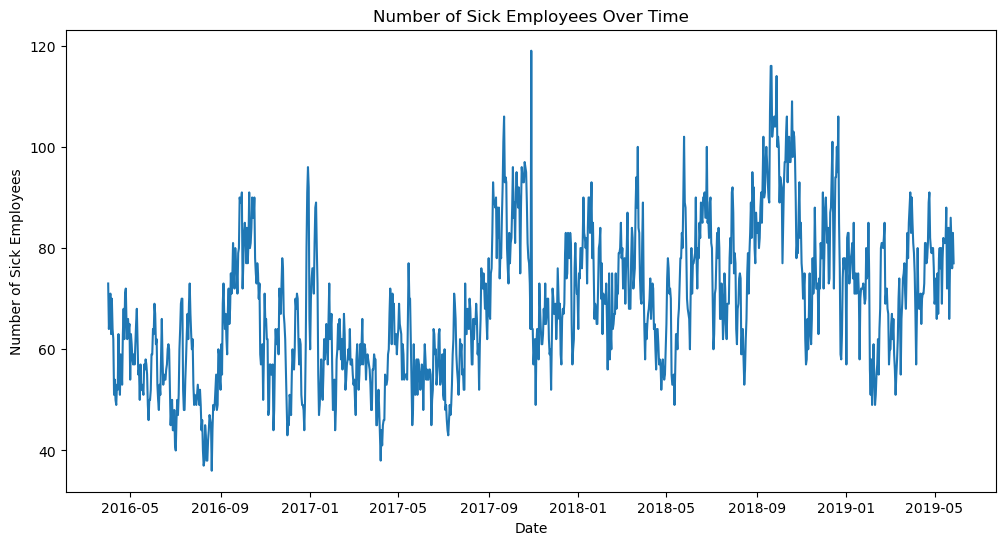

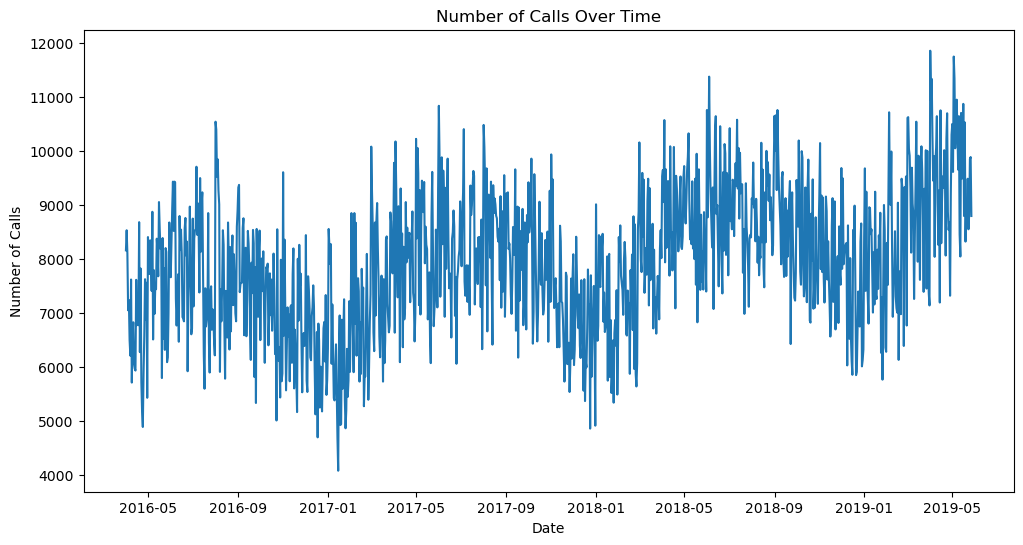

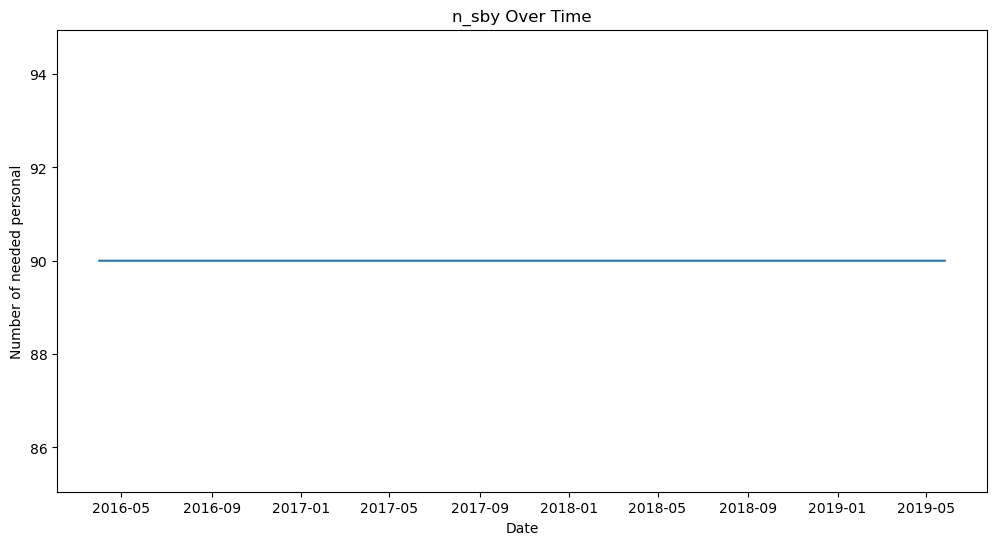

In [17]:
# Plot n_sick over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='date', y='n_sick')
plt.title('Number of Sick Employees Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Sick Employees')
plt.show()

# Plot calls over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='date', y='calls')
plt.title('Number of Calls Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Calls')
plt.show()

# Plot sby_need over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='date', y='n_sby')
plt.title('n_sby Over Time')
plt.xlabel('Date')
plt.ylabel('Number of needed personal')
plt.show()

# Datenvorbereitung

In [10]:
working_df = df.copy(deep=True)

print("Number NaN values:", working_df.isna().sum())

# Umgang mit fehlenden Werten
working_df = working_df.dropna()

# Feature Engineering
working_df['month'] = working_df['date'].dt.month
working_df['day_of_week'] = working_df['date'].dt.dayofweek

# Datenaufteilung
from sklearn.model_selection import train_test_split

X = working_df[['calls', 'n_duty', 'n_sby', 'n_sick', 'dafted', 'month', 'day_of_week']]
y = working_df['sby_need']  # Annahme: n_sick soll vorhergesagt werden

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Number NaN values: Unnamed: 0    0
date          0
n_sick        0
calls         0
n_duty        0
n_sby         0
sby_need      0
dafted        0
dtype: int64


## Baseline-Modell

Baseline MAE: 65.65563499113988


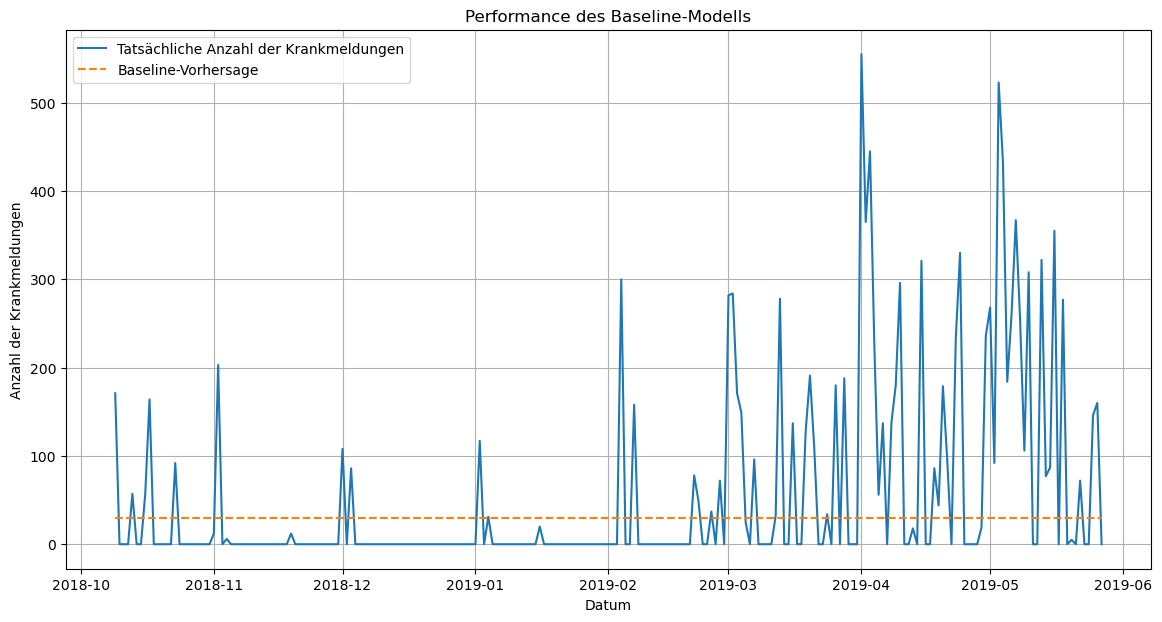

In [11]:
from sklearn.metrics import mean_absolute_error

train_size = int(len(working_df) * 0.8)
train, test = working_df.iloc[:train_size], working_df.iloc[train_size:]

# Baseline-Modell: Durchschnitt der Zielvariable im Trainingsset
mean_sick_train = train['sby_need'].mean()

test = test.copy() # Zum Verhindern der SettingWithCopyWarning
# Vorhersagen für das Testset mit dem Baseline-Modell
test['baseline_pred'] = mean_sick_train

# Berechnung des Mean Absolute Error (MAE) für das Baseline-Modell
mae_baseline = mean_absolute_error(test['sby_need'], test['baseline_pred'])
print(f'Baseline MAE: {mae_baseline}')

# Visualisierung der Performance des Baseline-Modells
plt.figure(figsize=(14, 7))
plt.plot(test['date'], test['sby_need'], label='Tatsächliche Anzahl der Krankmeldungen')
plt.plot(test['date'], test['baseline_pred'], label='Baseline-Vorhersage', linestyle='--')
plt.xlabel('Datum')
plt.ylabel('Anzahl der Krankmeldungen')
plt.title('Performance des Baseline-Modells')
plt.legend()
plt.grid(True)
plt.show()

## Erstellung und Evaluation des Vorhersagemodells

Model MAE: 1.0025108225108228
Best Model MAE: 1.0212093965505742

Feature importance:
n_sby: 0.0
day_of_week: 0.0002769796411799892
month: 0.0006703214123149242
n_sick: 0.0013435496018938211
n_duty: 0.011364624695559152
calls: 0.03642819104052501
dafted: 0.9499163336085271



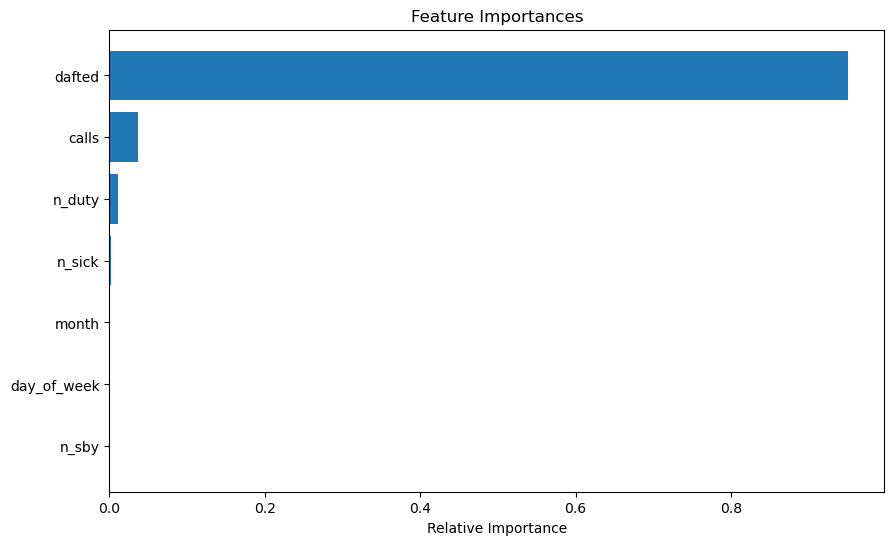

In [12]:
# Auswahl und Training eines Modells
from sklearn.ensemble import RandomForestRegressor

# Als einfacher Start. Bested Modell wird später rausgesucht
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f'Model MAE: {mean_absolute_error(y_test, y_pred)}')

# Hyperparameter-Tuning (optional)
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(model, param_grid, cv=5, scoring='neg_mean_absolute_error')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print(f'Best Model MAE: {mean_absolute_error(y_test, y_pred_best)}')

# Visualisierung und Kommunikation der Ergebnisse

# Feature Importance
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

print("\nFeature importance:")
[print(features[i] + ":", importances[i]) for i in indices]
print("")

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

# Datenexport

In [13]:
working_df.to_csv("../../data/processed/sickness_table.csv")